In [ ]:
!pip install optuna

In [ ]:
!pip install "optuna-integration[tfkeras]"

In [ ]:
"""
Optuna + LSTM untuk prediksi inflasi — versi audited & diperbaiki.

Perubahan utama dari versi asli:
1. FIX DATA LEAKAGE: split kronologis dilakukan SEBELUM scaling. Scaler hanya
   di-fit pada data train, lalu di-transform (bukan fit_transform) ke test.
2. Sliding window dibentuk SETELAH scaling per-split, bukan dari data yang
   sudah di-scale secara global.
3. Search space diperluas: n_layers, recurrent_dropout, clipnorm, loss
   function (mse/huber), pilihan RNN cell (LSTM/GRU).
4. study.optimize() dilengkapi: sampler eksplisit (TPESampler), pruner
   eksplisit (MedianPruner), storage SQLite agar studi bisa di-resume,
   dan penanganan trial gagal (NaN loss -> TrialPruned, bukan crash).
5. Baseline naive forecast ditambahkan sebagai pembanding sederhana.

Catatan: sesuaikan file_path dan city dengan kebutuhan Anda.
"""

import numpy as np
import pandas as pd
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from optuna_integration import TFKerasPruningCallback

tf.get_logger().setLevel('ERROR')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ============================================================
# STEP 1: LOAD & PREPARE DATASET
# ============================================================
file_path = "/content/ALL FIX - ALL2.csv"  # sesuaikan path
df = pd.read_csv(file_path)
df["Tanggal"] = pd.to_datetime(df["Tanggal"], dayfirst=False)

city = "KOTA BANDUNG"
data = (
    df[df["Kota"] == city]
    .sort_values("Tanggal", ascending=True)
    .reset_index(drop=True)
)
data = data[["Tanggal", "Inflasi", "UMR"]]
print(f"Dataset {city} berhasil dimuat! Total baris data: {len(data)}\n")

if len(data) < 60:
    print(
        "PERINGATAN: jumlah baris data cukup kecil untuk time series LSTM. "
        "Pertimbangkan TimeSeriesSplit multi-fold atau baseline klasik "
        "(ARIMA/Holt-Winters) sebagai pembanding."
    )

# ============================================================
# BASELINE: NAIVE FORECAST (y_pred[t] = y[t-1])
# ============================================================
naive_pred = data["Inflasi"].shift(1).dropna()
naive_true = data["Inflasi"].iloc[1:]
baseline_mse = mean_squared_error(naive_true, naive_pred)
print(f"Baseline naive forecast MSE: {baseline_mse:.6f}")
print("-> Model hasil tuning idealnya mengalahkan angka ini.\n")

FEATURE_COLS = ["Inflasi", "UMR"]
TARGET_COL = "Inflasi"
TARGET_IDX = FEATURE_COLS.index(TARGET_COL)


def get_scaler(scaler_type: str):
    if scaler_type == "robust":
        return RobustScaler()
    elif scaler_type == "minmax":
        return MinMaxScaler()
    else:
        return StandardScaler()


def make_windows(arr_x: np.ndarray, arr_y: np.ndarray, lag: int):
    X, y = [], []
    for i in range(lag, len(arr_x)):
        X.append(arr_x[i - lag: i])
        y.append(arr_y[i])
    return np.array(X), np.array(y)


# ============================================================
# OBJECTIVE FUNCTION
# ============================================================
def objective(trial: optuna.Trial) -> float:
    tf.keras.utils.set_random_seed(42)

    # ---- Search space ----
    cell_type = trial.suggest_categorical("cell_type", ["lstm", "gru"])
    n_layers = trial.suggest_int("n_layers", 1, 3)
    activation_func = trial.suggest_categorical("activation", ["tanh", "relu", "elu", "swish"])
    optimizer_name = trial.suggest_categorical("optimizer", ["adam", "adamw", "rmsprop", "nadam"])
    loss_name = trial.suggest_categorical("loss", ["mse", "huber"])
    scaler_type = trial.suggest_categorical("scaler_type", ["robust", "zscore", "minmax"])
    lag = trial.suggest_int("lag", 3, 24, step=3)

    units = [
        trial.suggest_categorical(f"units_l{i+1}", [16, 32, 64, 128])
        for i in range(n_layers)
    ]
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5, step=0.1)
    recurrent_dropout = trial.suggest_float("recurrent_dropout", 0.0, 0.3, step=0.1)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [8, 16, 32])
    clipnorm = trial.suggest_float("clipnorm", 0.5, 5.0, log=True)

    # ---- Split kronologis SEBELUM scaling (fix leakage) ----
    # Sisakan `lag` baris tambahan di awal test agar window pertama test
    # tetap bisa dibentuk dari data yang relevan.
    n = len(data)
    train_size = int(n * 0.8)
    train_raw = data.iloc[:train_size].reset_index(drop=True)
    test_raw = data.iloc[max(0, train_size - lag):].reset_index(drop=True)

    if len(train_raw) <= lag or len(test_raw) <= lag:
        raise optuna.TrialPruned("Lag terlalu besar untuk ukuran split ini.")

    scaler = get_scaler(scaler_type)
    train_scaled = scaler.fit_transform(train_raw[FEATURE_COLS])
    test_scaled = scaler.transform(test_raw[FEATURE_COLS])  # transform saja, tidak fit ulang

    X_train, y_train = make_windows(train_scaled, train_scaled[:, TARGET_IDX], lag)
    X_test, y_test = make_windows(test_scaled, test_scaled[:, TARGET_IDX], lag)

    # ---- Optimizer ----
    optimizer_map = {
        "adam": tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=clipnorm),
        "adamw": tf.keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=1e-4, clipnorm=clipnorm),
        "rmsprop": tf.keras.optimizers.RMSprop(learning_rate=learning_rate, clipnorm=clipnorm),
        "nadam": tf.keras.optimizers.Nadam(learning_rate=learning_rate, clipnorm=clipnorm),
    }
    optimizer = optimizer_map[optimizer_name]
    loss_fn = "mse" if loss_name == "mse" else tf.keras.losses.Huber()

    # ---- Bangun model dinamis n_layers ----
    RNNLayer = LSTM if cell_type == "lstm" else GRU
    layers = [Input(shape=(X_train.shape[1], X_train.shape[2]))]
    for i, u in enumerate(units):
        return_seq = i < n_layers - 1
        layers.append(
            RNNLayer(
                units=u,
                return_sequences=return_seq,
                activation=activation_func,
                recurrent_dropout=recurrent_dropout,
            )
        )
        layers.append(Dropout(dropout_rate))
    layers.append(Dense(units=1))

    model = Sequential(layers)
    model.compile(optimizer=optimizer, loss=loss_fn)

    early_stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    pruning_callback = TFKerasPruningCallback(trial, "val_loss")

    try:
        model.fit(
            X_train, y_train,
            validation_data=(X_test, y_test),
            epochs=200,
            batch_size=batch_size,
            shuffle=False,
            callbacks=[early_stop, pruning_callback],
            verbose=0,
        )
    except optuna.TrialPruned:
        raise
    except Exception as e:
        print(f"Trial {trial.number} gagal: {e}")
        raise optuna.TrialPruned(f"Training error: {e}")

    y_pred = model.predict(X_test, verbose=0)

    if np.isnan(y_pred).any():
        raise optuna.TrialPruned("Prediksi menghasilkan NaN.")

    # Inverse transform hanya kolom target
    def inverse_target(scaled_col: np.ndarray) -> np.ndarray:
        dummy = np.zeros((len(scaled_col), len(FEATURE_COLS)))
        dummy[:, TARGET_IDX] = scaled_col.ravel()
        return scaler.inverse_transform(dummy)[:, TARGET_IDX]

    y_pred_inverse = inverse_target(y_pred)
    y_test_inverse = inverse_target(y_test)

    mse = mean_squared_error(y_test_inverse, y_pred_inverse)
    trial.set_user_attr("mae", float(mean_absolute_error(y_test_inverse, y_pred_inverse)))
    return mse


# ============================================================
# STUDY: sampler, pruner, storage eksplisit
# ============================================================
if __name__ == "__main__":
    study = optuna.create_study(
        study_name=f"inflasi_lstm_{city.replace(' ', '_')}",
        direction="minimize",
        sampler=TPESampler(seed=42),
        pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=20),
        storage=f"sqlite:///optuna_inflasi_{city.replace(' ', '_')}.db",
        load_if_exists=True,
    )

    study.optimize(
        objective,
        n_trials=100,
        timeout=None,          # set misal 3600 (detik) jika ingin batas waktu
        catch=(Exception,),    # trial error tidak menghentikan seluruh studi
        show_progress_bar=True,
    )

    print("\n=== HASIL TUNING ===")
    print(f"Jumlah trial selesai : {len(study.trials)}")
    print(f"Best MSE             : {study.best_value:.6f}")
    print(f"Baseline naive MSE    : {baseline_mse:.6f}")
    print(f"Best params           : {study.best_params}")
    print(f"Best trial MAE        : {study.best_trial.user_attrs.get('mae')}")

    # Simpan hasil trial ke CSV untuk analisis lanjutan
    df_trials = study.trials_dataframe()
    df_trials.to_csv(f"optuna_trials_{city.replace(' ', '_')}.csv", index=False)
    print(f"\nSemua trial disimpan ke optuna_trials_{city.replace(' ', '_')}.csv")

Dataset KOTA BANDUNG berhasil dimuat! Total baris data: 312

Baseline naive forecast MSE: 0.799736
-> Model hasil tuning idealnya mengalahkan angka ini.



  0%|          | 0/100 [00:00<?, ?it/s]


=== HASIL TUNING ===
Jumlah trial selesai : 100
Best MSE             : 0.236862
Baseline naive MSE    : 0.799736
Best params           : {'cell_type': 'gru', 'n_layers': 3, 'activation': 'swish', 'optimizer': 'nadam', 'loss': 'huber', 'scaler_type': 'zscore', 'lag': 9, 'units_l1': 32, 'units_l2': 128, 'units_l3': 128, 'dropout_rate': 0.5, 'recurrent_dropout': 0.3, 'learning_rate': 0.003628700225554068, 'batch_size': 8, 'clipnorm': 3.9584411516367397}
Best trial MAE        : 0.3101589422955117

Semua trial disimpan ke optuna_trials_KOTA_BANDUNG.csv


MELATIH ULANG MODEL DENGAN PARAMETER TERBAIK - KOTA BANDUNG
{'cell_type': 'gru', 'n_layers': 3, 'activation': 'swish', 'optimizer': 'nadam', 'loss': 'huber', 'scaler_type': 'zscore', 'lag': 9, 'units_l1': 32, 'units_l2': 128, 'units_l3': 128, 'dropout_rate': 0.5, 'recurrent_dropout': 0.3, 'learning_rate': 0.003628700225554068, 'batch_size': 8, 'clipnorm': 3.9584411516367397}


Model: "sequential_100"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_199 (GRU)                   │ (None, 9, 32)          │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_224 (Dropout)           │ (None, 9, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_200 (GRU)                   │ (None, 9, 128)         │        62,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_225 (Dropout)           │ (None, 9, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_201 (GRU)                   │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_226 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_100 (Dense)               │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,865 (644.00 KB)

 Trainable params: 164,865 (644.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - loss: 0.2822 - val_loss: 0.1782
Epoch 2/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.2943 - val_loss: 0.1654
Epoch 3/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.2877 - val_loss: 0.1623
Epoch 4/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.2825 - val_loss: 0.1619
Epoch 5/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.2789 - val_loss: 0.1619
Epoch 6/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.2763 - val_loss: 0.1626
Epoch 7/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.2800 - val_loss: 0.1618
Epoch 8/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.2991 - val_loss: 0.1617
Epoch 9/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.2876 - val_loss: 0.1626
Epoch 10/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.2830 - val_loss: 0.1617
Epoch 11/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.2768 - val_loss: 0.1621
Epoch 12/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/ste

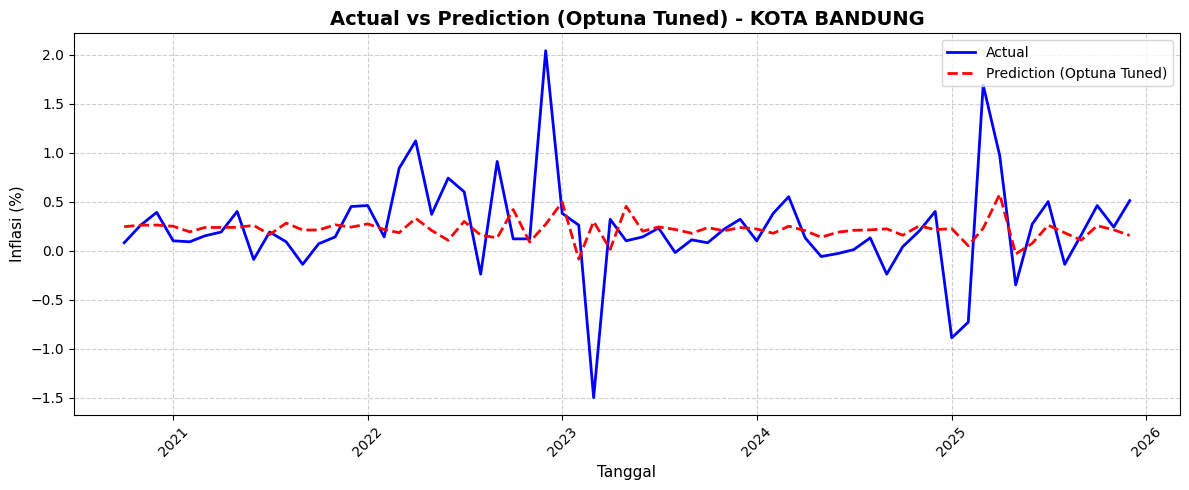


Grafik disimpan sebagai actual_vs_prediction_KOTA_BANDUNG.png


In [ ]:
"""
Re-train model final dengan hyperparameter terbaik dari Optuna + plot.
Versi diperbaiki — konsisten dengan optuna_lstm_inflasi_fixed.py.

Perubahan dari versi asli:
1. Menghapus duplikasi pembangunan model (versi asli membangun best_model
   dua kali; blok kedua meng-overwrite blok pertama dan diam-diam membuang
   activation function hasil tuning serta optimizer terbaik, kembali ke
   Adam default).
2. FIX DATA LEAKAGE: split kronologis sebelum scaling; scaler fit hanya
   di train, transform saja ke test — sama seperti file training.
3. Mendukung semua parameter hasil search space yang diperluas:
   cell_type (LSTM/GRU), n_layers dinamis, recurrent_dropout, clipnorm,
   loss (mse/huber).
4. Inverse transform ditangani lewat scaler multi-kolom yang sama.
5. Plot actual vs prediction tetap dipertahankan sesuai kode asli, dengan
   sumbu waktu (tanggal) bila tersedia agar lebih mudah dibaca.

Asumsi: variabel `study`, `data`, `city`, `FEATURE_COLS`, `TARGET_COL`,
`TARGET_IDX` sudah tersedia dari sesi Optuna sebelumnya (dari
optuna_lstm_inflasi_fixed.py). Jika dijalankan terpisah, definisikan ulang
di bagian bawah file ini.
"""

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# ============================================================
# GUARD: pastikan variabel dari sesi Optuna tersedia
# ============================================================
required_vars = ["study", "data", "city"]
missing = [v for v in required_vars if v not in dir()]
if missing:
    raise NameError(
        f"Variabel berikut belum tersedia: {missing}. "
        "Jalankan skrip training Optuna (optuna_lstm_inflasi_fixed.py) "
        "terlebih dahulu di sesi yang sama, atau definisikan ulang "
        "data/city/FEATURE_COLS secara manual."
    )

FEATURE_COLS = globals().get("FEATURE_COLS", ["Inflasi", "UMR"])
TARGET_COL = globals().get("TARGET_COL", "Inflasi")
TARGET_IDX = FEATURE_COLS.index(TARGET_COL)

best_params = study.best_params

print("=" * 60)
print(f"MELATIH ULANG MODEL DENGAN PARAMETER TERBAIK - {city}")
print("=" * 60)
print(best_params)

# ============================================================
# 1. Split kronologis SEBELUM scaling (fix leakage)
# ============================================================
lag = best_params["lag"]
n = len(data)
train_size = int(n * 0.8)
train_raw = data.iloc[:train_size].reset_index(drop=True)
test_raw = data.iloc[max(0, train_size - lag):].reset_index(drop=True)

if len(train_raw) <= lag or len(test_raw) <= lag:
    raise ValueError("Lag terbaik terlalu besar untuk ukuran split ini.")

# ============================================================
# 2. Scaler: fit HANYA di train, transform ke test
# ============================================================
scaler_type = best_params["scaler_type"]
if scaler_type == "robust":
    scaler = RobustScaler()
elif scaler_type == "minmax":
    scaler = MinMaxScaler()
else:
    scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_raw[FEATURE_COLS])
test_scaled = scaler.transform(test_raw[FEATURE_COLS])


def make_windows(arr_x: np.ndarray, arr_y: np.ndarray, lag: int):
    X, y = [], []
    for i in range(lag, len(arr_x)):
        X.append(arr_x[i - lag: i])
        y.append(arr_y[i])
    return np.array(X), np.array(y)


X_train, y_train = make_windows(train_scaled, train_scaled[:, TARGET_IDX], lag)
X_test, y_test = make_windows(test_scaled, test_scaled[:, TARGET_IDX], lag)

# Tanggal yang berpadanan dengan y_test, untuk sumbu-x plot nanti
test_dates = test_raw["Tanggal"].iloc[lag:].reset_index(drop=True)

# ============================================================
# 3. Optimizer terbaik (dengan clipnorm, konsisten dgn training)
# ============================================================
best_opt_name = best_params["optimizer"]
best_lr = best_params["learning_rate"]
clipnorm = best_params.get("clipnorm", None)
clip_kwargs = {"clipnorm": clipnorm} if clipnorm is not None else {}

optimizer_map = {
    "adam": tf.keras.optimizers.Adam(learning_rate=best_lr, **clip_kwargs),
    "adamw": tf.keras.optimizers.AdamW(learning_rate=best_lr, weight_decay=1e-4, **clip_kwargs),
    "rmsprop": tf.keras.optimizers.RMSprop(learning_rate=best_lr, **clip_kwargs),
    "nadam": tf.keras.optimizers.Nadam(learning_rate=best_lr, **clip_kwargs),
}
best_optimizer = optimizer_map[best_opt_name]

loss_name = best_params.get("loss", "mse")
loss_fn = "mse" if loss_name == "mse" else tf.keras.losses.Huber()

# ============================================================
# 4. Bangun ulang arsitektur SESUAI hasil tuning (n_layers dinamis)
# ============================================================
cell_type = best_params.get("cell_type", "lstm")
RNNLayer = LSTM if cell_type == "lstm" else GRU
n_layers = best_params.get("n_layers", 2)
activation_func = best_params.get("activation", "tanh")
dropout_rate = best_params["dropout_rate"]
recurrent_dropout = best_params.get("recurrent_dropout", 0.0)

layers = [Input(shape=(X_train.shape[1], X_train.shape[2]))]
for i in range(n_layers):
    units_key = f"units_l{i + 1}"
    return_seq = i < n_layers - 1
    layers.append(
        RNNLayer(
            units=best_params[units_key],
            return_sequences=return_seq,
            activation=activation_func,
            recurrent_dropout=recurrent_dropout,
        )
    )
    layers.append(Dropout(dropout_rate))
layers.append(Dense(units=1))

best_model = Sequential(layers)
best_model.compile(optimizer=best_optimizer, loss=loss_fn)
best_model.summary()

# ============================================================
# 5. Training model final (tanpa pruning callback — bukan trial lagi)
# ============================================================
early_stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

history = best_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=best_params["batch_size"],
    shuffle=False,
    callbacks=[early_stop],
    verbose=1,
)

# ============================================================
# 6. Prediksi & inverse transform (multi-kolom, benar)
# ============================================================
y_pred = best_model.predict(X_test, verbose=0)


def inverse_target(scaled_col: np.ndarray) -> np.ndarray:
    dummy = np.zeros((len(scaled_col), len(FEATURE_COLS)))
    dummy[:, TARGET_IDX] = scaled_col.ravel()
    return scaler.inverse_transform(dummy)[:, TARGET_IDX]


y_pred_inverse = inverse_target(y_pred)
y_test_inverse = inverse_target(y_test)

mse_final = mean_squared_error(y_test_inverse, y_pred_inverse)
mae_final = mean_absolute_error(y_test_inverse, y_pred_inverse)
rmse_final = np.sqrt(mse_final)

# Bandingkan dengan baseline naive jika tersedia dari sesi training
baseline_mse = globals().get("baseline_mse", None)

print("\n" + "=" * 60)
print("EVALUASI MODEL AKHIR (Optuna Tuned)")
print("=" * 60)
print(f"MSE  : {mse_final:.4f}")
print(f"RMSE : {rmse_final:.4f}")
print(f"MAE  : {mae_final:.4f}")
if baseline_mse is not None:
    print(f"Baseline naive MSE : {baseline_mse:.4f}")
    verdict = "mengalahkan" if mse_final < baseline_mse else "TIDAK mengalahkan"
    print(f"-> Model tuned {verdict} baseline naive forecast.")

# ============================================================
# 7. VISUALISASI ACTUAL vs PREDICTION
# ============================================================
plt.figure(figsize=(12, 5))

x_axis = test_dates if len(test_dates) == len(y_test_inverse) else np.arange(len(y_test_inverse))

plt.plot(x_axis, y_test_inverse, color="blue", linewidth=2, label="Actual")
plt.plot(x_axis, y_pred_inverse, color="red", linestyle="--", linewidth=2, label="Prediction (Optuna Tuned)")

plt.title(f"Actual vs Prediction (Optuna Tuned) - {city}", fontsize=14, fontweight="bold")
plt.xlabel("Tanggal" if len(test_dates) == len(y_test_inverse) else "Data Testing (Bulan ke-)", fontsize=11)
plt.ylabel("Inflasi (%)", fontsize=11)
if len(test_dates) == len(y_test_inverse):
    plt.xticks(rotation=45)
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(f"actual_vs_prediction_{city.replace(' ', '_')}.png", dpi=150)
plt.show()

print(f"\nGrafik disimpan sebagai actual_vs_prediction_{city.replace(' ', '_')}.png")